# Прогнозирование активности пользователей в ленте новостей

**Задача:** оценить будущую почасовую активность приложения и проверить, достаточно ли точен прогноз для планирования нагрузки.

Модель: Orbit DLT, суточная сезонность (`seasonality=24`). Сравниваются прогнозы по всей истории и по периоду с 21 июня 2026 года, затем проводится бэктестирование на горизонте 7 дней.

**Важно:** расчёты и графики ниже сохранены из первоначального запуска. Исходная учебная база сейчас недоступна, поэтому ноутбук не запускался повторно. В версии для GitHub изменены только оформление, пояснения и способ передачи параметров подключения. Численные результаты не подменялись.

[Подробное описание и выводы](../README.md).

In [1]:
import orbit #общий пакет
from orbit.models import DLT #один из вариантов модели
from orbit.diagnostics.plot import plot_predicted_data, plot_predicted_components #для рисования предсказаний

#общие штуки для кручения данных
import pandas as pd
import pandahouse as ph
import numpy as np
import os

#общие штуки для рисования
import seaborn as sns
import matplotlib.pyplot as plt
import arviz as az #это полезно для визуализации MCMC

from orbit.diagnostics.backtest import BackTester #основной класс для бэктестинга 
from orbit.utils.params_tuning import grid_search_orbit #для подбора оптимальных параметров

In [2]:
# Для повторного запуска нужен доступ к соответствующей базе ClickHouse.
# Учётные данные в публичном ноутбуке не хранятся.
connection = {
    "host": os.environ["CLICKHOUSE_URL"],
    "user": os.getenv("CLICKHOUSE_USER", "student"),
    "password": os.environ["CLICKHOUSE_PASSWORD"],
    "database": os.getenv("CLICKHOUSE_DATABASE", "simulator_20260620"),
}

In [3]:
q = """
SELECT 
    toStartOfHour(time) AS hour_time, 
    COUNT(action) AS actions
FROM simulator_20260620.feed_actions 
GROUP BY hour_time 
ORDER BY hour_time
"""

df = ph.read_clickhouse(q, connection=connection)
df.head()


,hour_time,actions
0,2026-05-02 00:00:00,22
1,2026-05-02 01:00:00,32
2,2026-05-02 02:00:00,24
3,2026-05-02 03:00:00,11
4,2026-05-02 04:00:00,18


В качестве метрики выбрала активность пользователей (view и like). Для оценки будущей нагрузки на сервер важно количество действий пользователей, поскольку именно они порождают обращения к серверу.

Поскольку инженерам и девопсам нужно знать пиковые нагрузки на сервера, чтобы предотвратить зависание приложения, был выбран часовой график. На нем они увидят конкретные часы, когда нагрузка максимальна.


In [4]:
dlt = DLT(response_col="actions",
          date_col="hour_time", 
          seasonality=24, 
          estimator="stan-map",
          n_bootstrap_draws=1000) 

2026-07-13 22:11:50 - orbit - INFO - Optimizing (PyStan) with algorithm: LBFGS.


In [5]:
dlt.fit(df)

In [6]:
future_df = dlt.make_future_df(periods=24*30) #прогноз на месяц вперед
future_df.head()

,hour_time
0,2026-07-14 02:00:00
1,2026-07-14 03:00:00
2,2026-07-14 04:00:00
3,2026-07-14 05:00:00
4,2026-07-14 06:00:00


In [7]:
# Делаем прогноз

predicted_df = dlt.predict(df=future_df)
predicted_df.head()

,hour_time,prediction_5,prediction,prediction_95
0,2026-07-14 02:00:00,-6419.437540,-3010.952128,768.170682
1,2026-07-14 03:00:00,-12908.024567,-7931.481572,-3133.735613
2,2026-07-14 04:00:00,-14108.404900,-8960.310991,-3455.530476
3,2026-07-14 05:00:00,-10130.031352,-3865.140390,2867.314486
4,2026-07-14 06:00:00,-6642.919567,61.530228,6998.168903


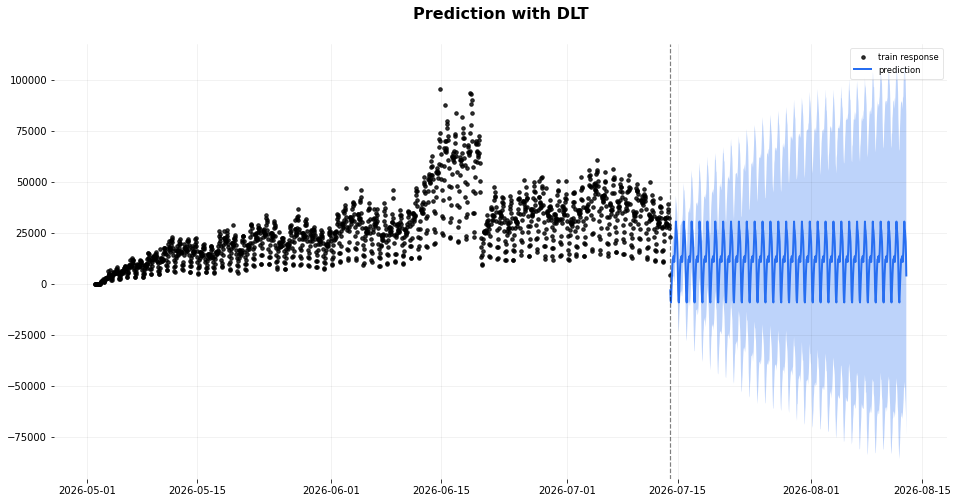

In [8]:
_ = plot_predicted_data(df, predicted_df, "hour_time", 'actions', title='Prediction with DLT')

In [9]:
predicted_df = dlt.predict(df=future_df, 
                           decompose=True) 
predicted_df.head()

,hour_time,prediction_5,prediction,prediction_95,trend_5,trend,trend_95,seasonality_5,seasonality,seasonality_95,regression_5,regression,regression_95
0,2026-07-14 02:00:00,-6860.063092,-3010.952128,786.597881,7864.236908,11713.347872,15510.897881,-14724.3,-14724.3,-14724.3,0.0,0.0,0.0
1,2026-07-14 03:00:00,-12771.796298,-7931.481572,-2963.710832,6873.003702,11713.318428,16681.089168,-19644.8,-19644.8,-19644.8,0.0,0.0,0.0
2,2026-07-14 04:00:00,-14911.065617,-8960.310991,-2901.737721,5762.534383,11713.289009,17771.862279,-20673.6,-20673.6,-20673.6,0.0,0.0,0.0
3,2026-07-14 05:00:00,-10121.715661,-3865.140390,2633.445291,5456.684339,11713.259610,18211.845291,-15578.4,-15578.4,-15578.4,0.0,0.0,0.0
4,2026-07-14 06:00:00,-6492.068092,61.530228,7249.173268,5159.631908,11713.230228,18900.873268,-11651.7,-11651.7,-11651.7,0.0,0.0,0.0


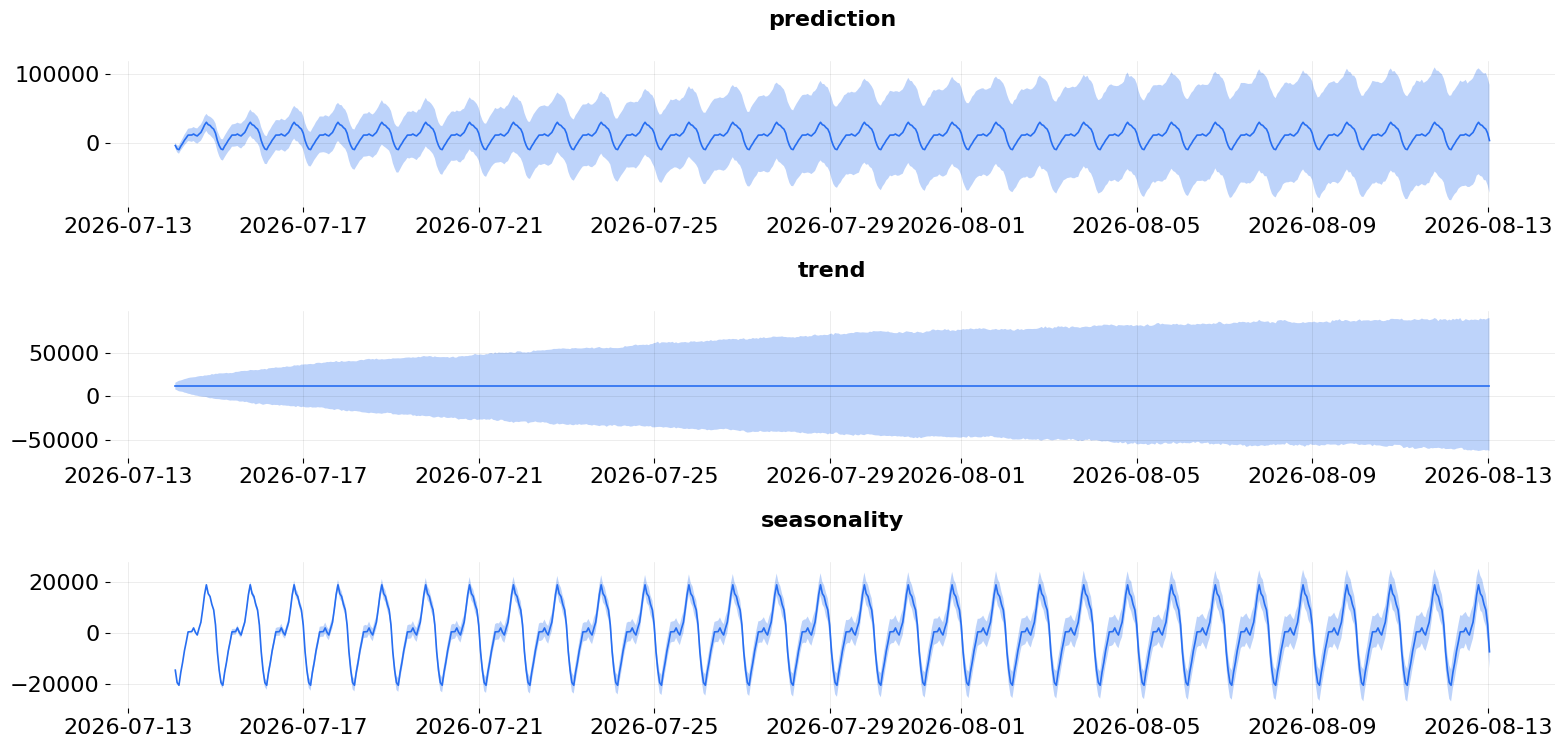

In [10]:
_ = plot_predicted_components(predicted_df, "hour_time", plot_components=['prediction', 'trend', 'seasonality'])

## Выводы по первой модели

При таком построении модели графики выглядят очень шумными, а доверительный интервал раздувается и уходит сильно в минус (до -75 000 действий в час). Так как количество действий не может быть отрицательным, это может говорить о высокой неопределённости модели и её недостаточной пригодности для долгосрочного прогнозирования.

Также стоит отметить, что модель обучалась на всей истории,в которой данные очень нестабильны (всплески и падения активности после рекламы, флэшмоба м проблем с приложением 20 июня). Из-за такого количества аномалий возможно модель не понимает, куда на самом деле идет тренд. Чем дальше в будущее (к августу), тем сильнее расширяется доверительный интервал.

In [11]:
# Оставляем только стабильный период после флэшмобов и аварии
df_clean = df[df['hour_time'] >= '2026-06-21 00:00:00'].reset_index(drop=True)

# Обучаем модель на чистых данных
dlt.fit(df_clean)

In [12]:
future_df_clean = dlt.make_future_df(periods=24*7) #горизонт будет 7 дней - то есть 7 раз по 24 часа
future_df_clean.head()

,hour_time
0,2026-07-14 02:00:00
1,2026-07-14 03:00:00
2,2026-07-14 04:00:00
3,2026-07-14 05:00:00
4,2026-07-14 06:00:00


In [13]:
predicted_df_clean = dlt.predict(df=future_df_clean)
predicted_df_clean.head()

,hour_time,prediction_5,prediction,prediction_95
0,2026-07-14 02:00:00,1128.687311,6234.80454,11407.355615
1,2026-07-14 03:00:00,-4370.593184,1200.74954,6522.728430
2,2026-07-14 04:00:00,-5305.996882,227.89454,5887.692225
3,2026-07-14 05:00:00,-511.942721,5171.83954,11028.678822
4,2026-07-14 06:00:00,3571.080341,8928.60454,14677.682005


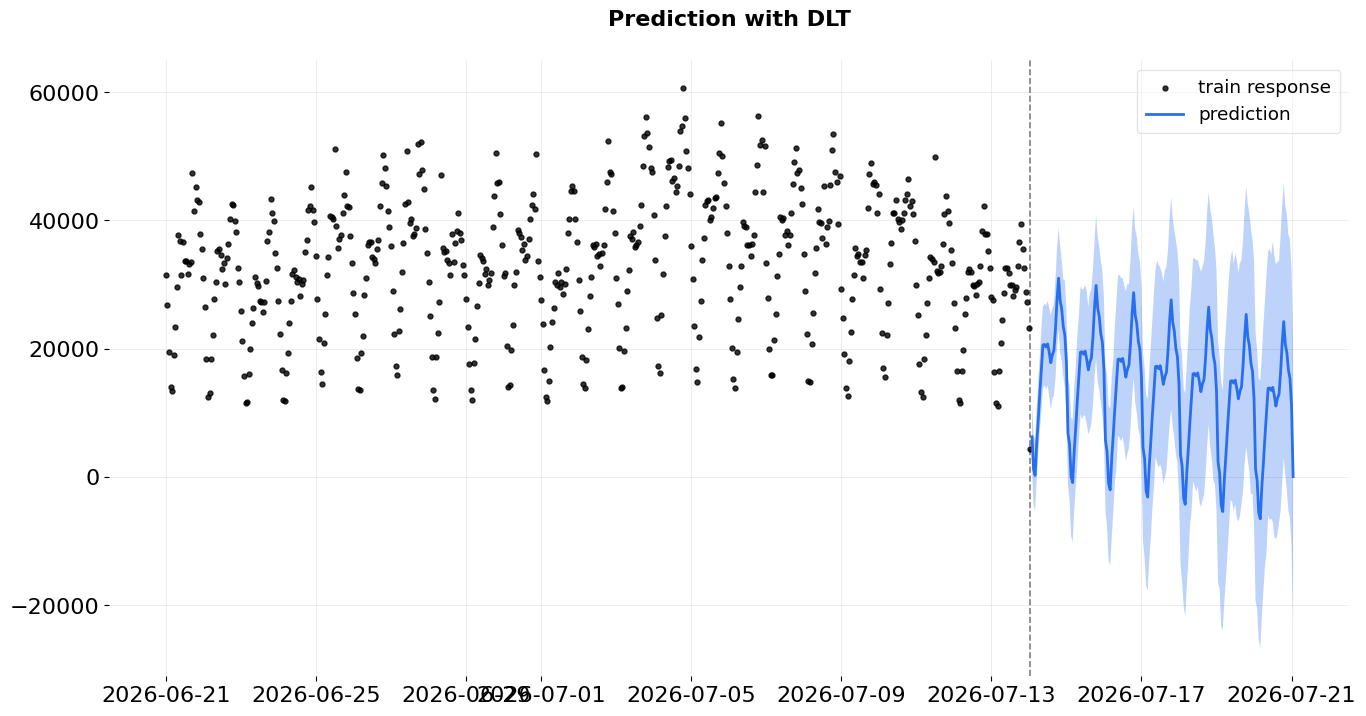

In [14]:
_ = plot_predicted_data(df_clean, predicted_df_clean, "hour_time", 'actions', title='Prediction with DLT')

In [15]:
predicted_df_clean = dlt.predict(df=future_df_clean, 
                           decompose=True) #говорит, что нам нужна декомпозиция предсказания
predicted_df_clean.head()

,hour_time,prediction_5,prediction,prediction_95,trend_5,trend,trend_95,seasonality_5,seasonality,seasonality_95,regression_5,regression,regression_95
0,2026-07-14 02:00:00,1124.715133,6234.80454,11464.350723,11795.315133,16905.40454,22134.950723,-10670.60,-10670.60,-10670.60,0.0,0.0,0.0
1,2026-07-14 03:00:00,-4124.485677,1200.74954,6601.809264,11533.114323,16858.34954,22259.409264,-15657.60,-15657.60,-15657.60,0.0,0.0,0.0
2,2026-07-14 04:00:00,-5455.973844,227.89454,5838.421427,11127.426156,16811.29454,22421.821427,-16583.40,-16583.40,-16583.40,0.0,0.0,0.0
3,2026-07-14 05:00:00,37.643232,5171.83954,10972.070854,11630.043232,16764.23954,22564.470854,-11592.40,-11592.40,-11592.40,0.0,0.0,0.0
4,2026-07-14 06:00:00,3332.259206,8928.60454,14842.185444,11120.839206,16717.18454,22630.765444,-7788.58,-7788.58,-7788.58,0.0,0.0,0.0


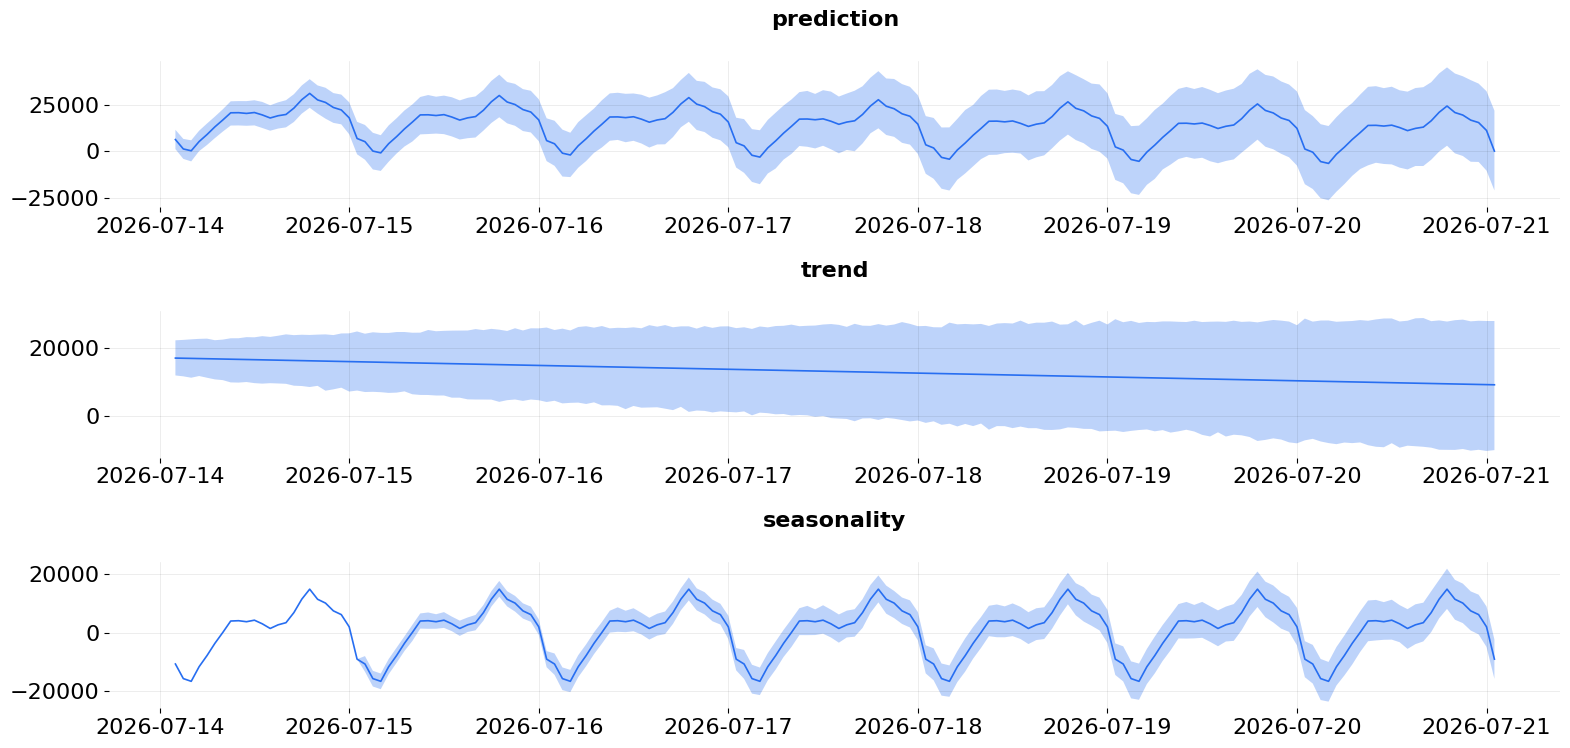

In [16]:
_ = plot_predicted_components(predicted_df_clean, "hour_time", plot_components=['prediction', 'trend', 'seasonality'])

## Промежуточные выводы по второй модели

В ходе исследования было обнаружено, что в данных приложения до 20 июня существует множество аномалий, повлекших за собой изменения в поведении метрик. Использование данных до этой даты приводило к сильному искажению тренда и неадекватному расширению доверительных интервалов до отрицательных значений. После исключения периода до 21 июня модель обучается только на стабильном участке временного ряда.

После очистки данных доверительные интервалы стали заметно уже и прогноз стал стабильнее, однако нижняя граница доверительного интервала всё ещё местами принимает отрицательные значения, что говорит о сохраняющейся неопределённости модели.

Также из-за уменьшения обучающей выборки до ~22 дней, горизонт прогнозирования пришлось сократить до 7 дней. Из-за сокращения обучающей выборки становится сложно прогнозировать на горизонте 30 дней. Для такого горизонта модели не хватает истории, поэтому неопределённость прогноза возрастает.

## Проверка качества модели

In [17]:
bt_exp = BackTester(
    model=dlt,
    df=df_clean,
    min_train_len=24*14, #начнем обучение с 2 недель
    incremental_len=24, 
    forecast_len=24*7, #из-за небольшого объема данных для надежной проверки пришлось сократить горизонт прогнозирования до 7 дней
    window_type="expanding"
)

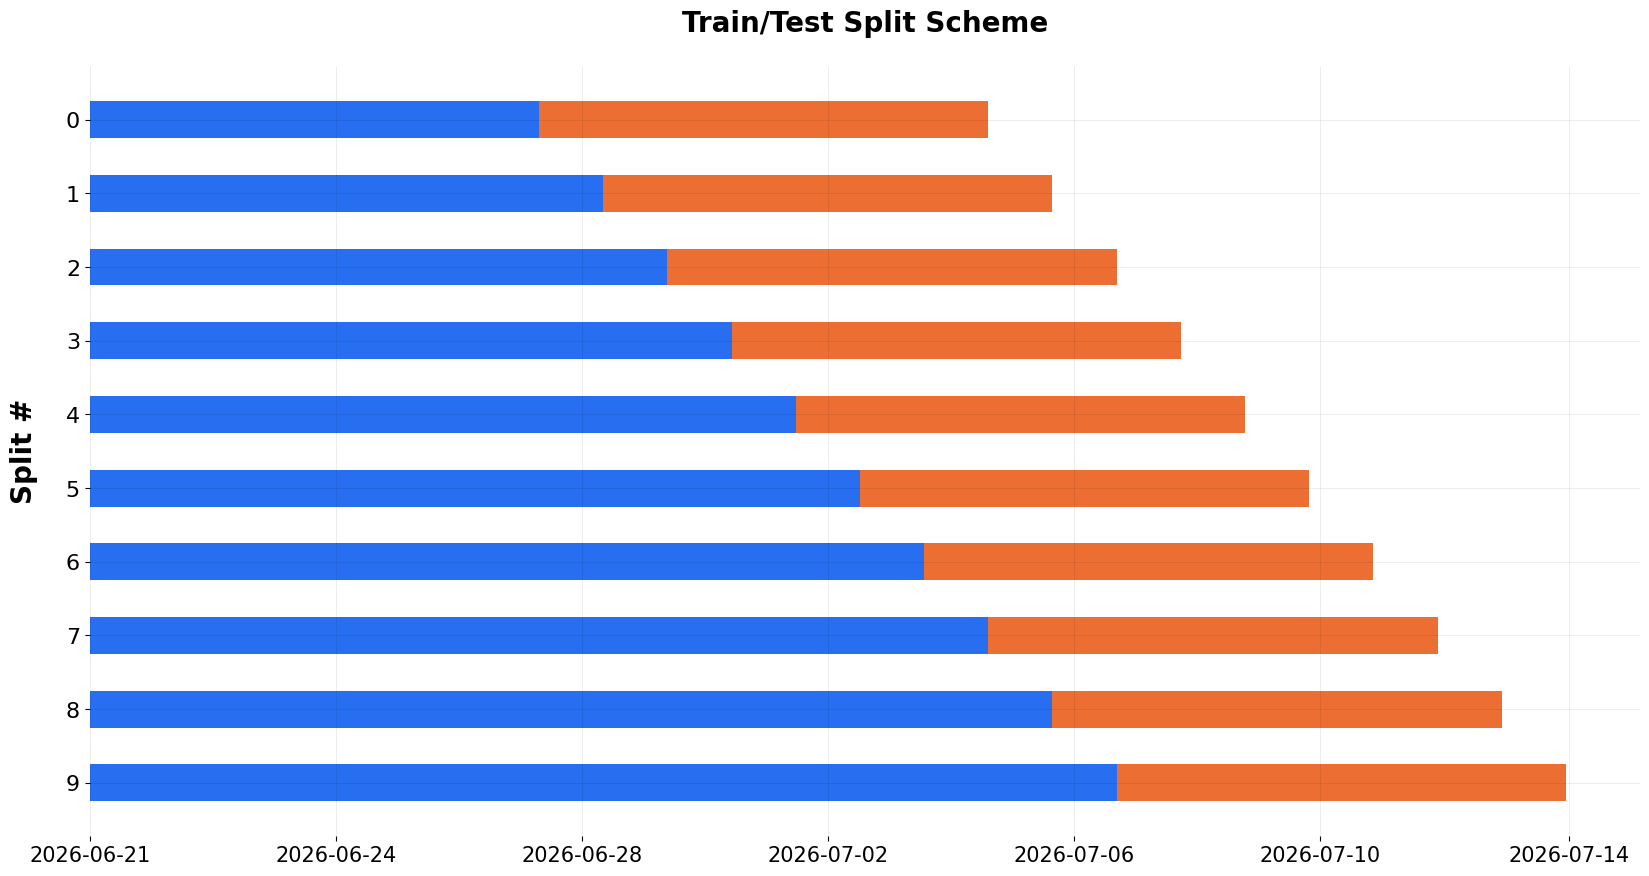

In [18]:
bt_exp.plot_scheme()

In [19]:
bt_exp.fit_predict() 
bt_exp.score()

,metric_name,metric_values,is_training_metric
0,smape,1.969244e-01,False
1,wmape,1.902065e-01,False
2,mape,2.085004e-01,False
3,mse,7.774144e+07,False
4,mae,6.708839e+03,False
5,rmsse,1.824370e+00,False


In [20]:
# попробуем посмотреть как выглядит прогноз на сутки вперед
bt_exp_2 = BackTester(
    model=dlt,
    df=df_clean,
    min_train_len=24*7,
    incremental_len=24, 
    forecast_len=24,
    window_type="expanding"
)

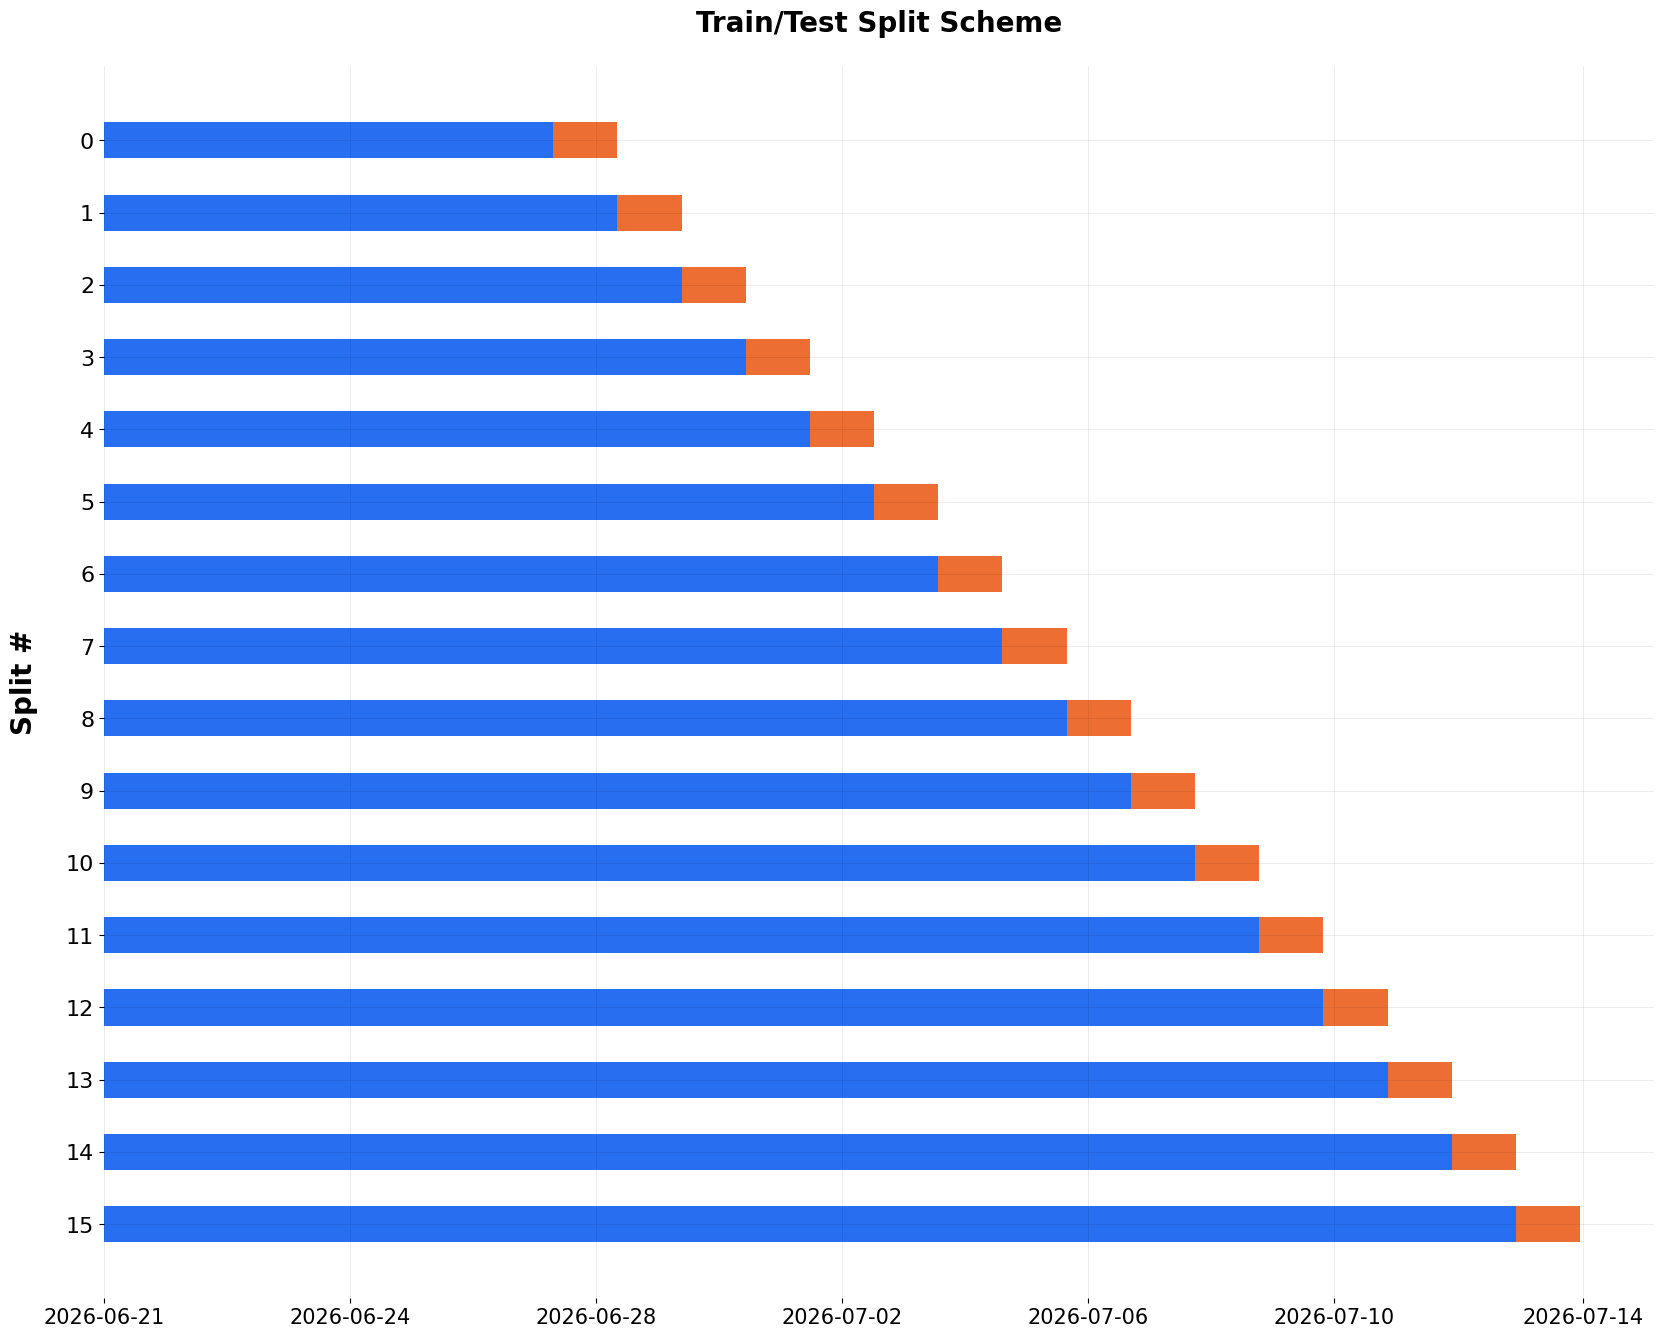

In [21]:
bt_exp_2.plot_scheme()

В первоначальном ноутбуке запуск суточного бэктеста был записан как текст Markdown, поэтому численные результаты для прогноза на 24 часа в сохранённом файле отсутствуют. Схема проверки приведена выше, но значения ошибки не публикуются без подтверждённого вывода.

В качестве основной проверки качества использовался горизонт **7 дней**. Сравнение с суточным горизонтом было запланировано, однако без сохранённого результата нельзя утверждать, насколько именно изменилась ошибка.

In [22]:
# посмотрим оптимальные параметры

best_params, tuned_df = grid_search_orbit(param_grid={"damped_factor": np.arange(0.1, 1.0, 0.1)}, #наш параметр
                                        model=dlt,
                                        df=df_clean,
                                        min_train_len=24*14,
                                        incremental_len=24,
                                        forecast_len=24*7,
                                        metrics=None,
                                        criteria="min",
                                        verbose=True)

2026-07-13 22:12:01 - orbit - INFO - tuning hyper-params {'damped_factor': 0.1}
2026-07-13 22:12:01 - orbit - INFO - Optimizing (PyStan) with algorithm: LBFGS.
2026-07-13 22:12:03 - orbit - INFO - tuning metric:0.21133
2026-07-13 22:12:03 - orbit - INFO - tuning hyper-params {'damped_factor': 0.2}
2026-07-13 22:12:03 - orbit - INFO - Optimizing (PyStan) with algorithm: LBFGS.
2026-07-13 22:12:04 - orbit - INFO - tuning metric:0.19079
2026-07-13 22:12:04 - orbit - INFO - tuning hyper-params {'damped_factor': 0.30000000000000004}
2026-07-13 22:12:04 - orbit - INFO - Optimizing (PyStan) with algorithm: LBFGS.
2026-07-13 22:12:05 - orbit - INFO - tuning metric:0.1816
2026-07-13 22:12:05 - orbit - INFO - tuning hyper-params {'damped_factor': 0.4}
2026-07-13 22:12:05 - orbit - INFO - Optimizing (PyStan) with algorithm: LBFGS.
2026-07-13 22:12:06 - orbit - INFO - tuning metric:0.22027
2026-07-13 22:12:06 - orbit - INFO - tuning hyper-params {'damped_factor': 0.5}
2026-07-13 22:12:06 - orbit -

In [23]:
best_params

[{'damped_factor': 0.30000000000000004}]

In [24]:
tuned_df

,damped_factor,metrics
0,0.1,0.211333
1,0.2,0.190791
2,0.3,0.181605
3,0.4,0.220267
4,0.5,0.194305
5,0.6,0.194355
6,0.7,0.194361
7,0.8,0.194302
8,0.9,0.194312


В рамках проведенного бэктестинга наилучшее качество показала модель с damped_factor = 0.3. Это могло бы значить, что для рассматриваемого участка временного ряда более сильное затухание тренда позволило получить меньшую ошибку прогноза. И быть связано с тем, что после окончания маркетинговых активностей рост пользовательской активности стал менее выраженным, поэтому модель, которая быстрее ослабляет влияние тренда, лучше соответствует наблюдаемым данным.

Однако различия между большинством вариантов невелики, а важно помнить, что объем исторических данных итак был ограничен, а затем и сокращен мной, поэтому полученное значение не следует рассматривать как оптимальное. Оно отражает наилучший результат именно для данного набора данных и выбранной схемы бэктестинга.

## Выводы

По сохранённому семидневному бэктесту sMAPE составила около **19,7%**, WMAPE около **19,0%**, а RMSSE равна **1,82**. Значение RMSSE выше 1 указывает на высокую ошибку относительно масштаба наивного прогноза, используемого для нормировки. Для практического применения нужна дополнительная проверка с прямым сравнением базовых моделей.

Данные содержат резкие изменения активности, а после исключения раннего периода история обучения становится короткой. Для продолжения исследования нужны более длительный ряд, корректная обработка неполного последнего дня и сравнение с простыми базовыми прогнозами. Возможное улучшение модели: учитывать известные маркетинговые и технические события как дополнительные признаки.

Подбор `damped_factor` показал наименьшую ошибку для **0,3** среди проверенных значений. Это результат конкретной схемы бэктестинга, не гарантирующий такого же качества на новых данных.